# Airline review clustering and text similarity

Course assignment for Machine Learning (NUS-ISS): unsupervised learning, feature engineering, and text vectorisation.

**Dataset:** [Airlines Review Dataset](https://www.kaggle.com/datasets/elijahconnectng/airlines-review-dataset) (Elijah Alabi, Kaggle, Apache 2.0). The file `data/airlines_reviews.csv` is the extracted `airlines_reviews.csv` from the Kaggle download (8,100 reviews, 17 columns). It covers passenger reviews of 10 airlines, with service scores and a free-text review.

**This notebook does four things:**

1. Clean the table and build numeric features (scaling, binning, one-hot encoding, PCA).
2. Fit and compare K-Means, hierarchical clustering, and DBSCAN on the rating features.
3. Build a Bag-of-Words matrix, a TF-IDF matrix, and cosine similarities between reviews.
4. Save the figures in `figures/` and the metric tables in `outputs/`.

**Worked calculations** are printed for standardisation, a PCA score, TF-IDF, and cosine similarity, then the same formulas are applied to the full dataset.

Part 4 of the brief (CNN image classification) is a bonus task and needs an image dataset. These reviews do not contain images, so that part is not trained here.

The technical report (PDF) should be written from these results in your own words. Section 12 lists which notebook results map to each part of the brief.

## 1. Setup

Run this notebook from the project folder `CA_machine_learning`, so `data/airlines_reviews.csv` is found. `RESULTS` collects the numbers used in the final summary.

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures"
OUT = ROOT / "outputs"
FIG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

RATING_COLS = [
    "Seat Comfort",
    "Staff Service",
    "Food & Beverages",
    "Inflight Entertainment",
    "Value For Money",
    "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort",
    "Staff Service",
    "Food & Beverages",
    "Inflight Entertainment",
]
RANDOM_STATE = 42
RESULTS = {}


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Data file:", DATA_PATH)
print("Exists:", DATA_PATH.exists())

Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv
Exists: True


## 2. Load the data

Numeric columns are the 1–5 service scores and the 1–10 overall score. `Reviews` is the text field used later. `Recommended` is kept for interpretation after clustering. It is not used as an input feature, so the clusters are not told the recommendation label in advance.

In [ ]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
display(raw.head(3))
print("Dtypes:")
display(raw.dtypes.to_frame("dtype"))
print("Missing values:")
display(raw.isnull().sum().to_frame("missing"))

## 3. Exploratory analysis

The plots below check three things that affect the later models: whether any column is empty, whether overall scores are polarised, and whether the rating columns share the same scale.

In [3]:
print("Duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate review texts:", int(raw["Reviews"].duplicated().sum()))
print("Airlines:")
display(raw["Airline"].value_counts().to_frame("reviews"))
print("Cabin class:")
display(raw["Class"].value_counts().to_frame("reviews"))
print("Traveller type:")
display(raw["Type of Traveller"].value_counts().to_frame("reviews"))
print("Recommended:")
display(raw["Recommended"].value_counts().to_frame("reviews"))
print("Verified values (watch for non true/false entries):")
display(raw["Verified"].value_counts().to_frame("reviews"))
print("Rating ranges:")
display(raw[RATING_COLS].agg(["min", "max", "mean", "std"]).round(3))

extreme_share = raw["Overall Rating"].isin([1, 2, 9, 10]).mean()
RESULTS["extreme_overall_share"] = float(extreme_share)
print(
    f"Share of reviews with overall rating in {{1, 2, 9, 10}}: {extreme_share:.1%}"
)

Duplicate rows: 0
Duplicate review texts: 1
Airlines:


,reviews
Airline,
Turkish Airlines,1685
Qatar Airways,1624
Emirates,1350
Singapore Airlines,972
Air France,798
Cathay Pacific Airways,744
EVA Air,281
All Nippon Airways,258
Japan Airlines,201


Cabin class:


,reviews
Class,
Economy Class,5504
Business Class,2104
Premium Economy,371
First Class,121


Traveller type:


,reviews
Type of Traveller,
Solo Leisure,3237
Couple Leisure,1899
Family Leisure,1551
Business,1413


... (3 outputs left out)

,reviews
Verified,
True,6216
False,1881
*Unverified*,1
NotVerified,1
we do appreciate you bringing this matter to our attention. Please accept my apologies for not having met your expectations; I do hope that we can leave you and your family with a more positive impression on your future flights with us,1


Rating ranges:


,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating
min,1.000,1.000,1.000,0.000,1.000,1.000
max,5.000,5.000,5.000,5.000,5.000,10.000
mean,3.415,3.570,3.384,3.637,3.149,5.632
std,1.397,1.527,1.456,1.310,1.589,3.524


Share of reviews with overall rating in {1, 2, 9, 10}: 63.8%


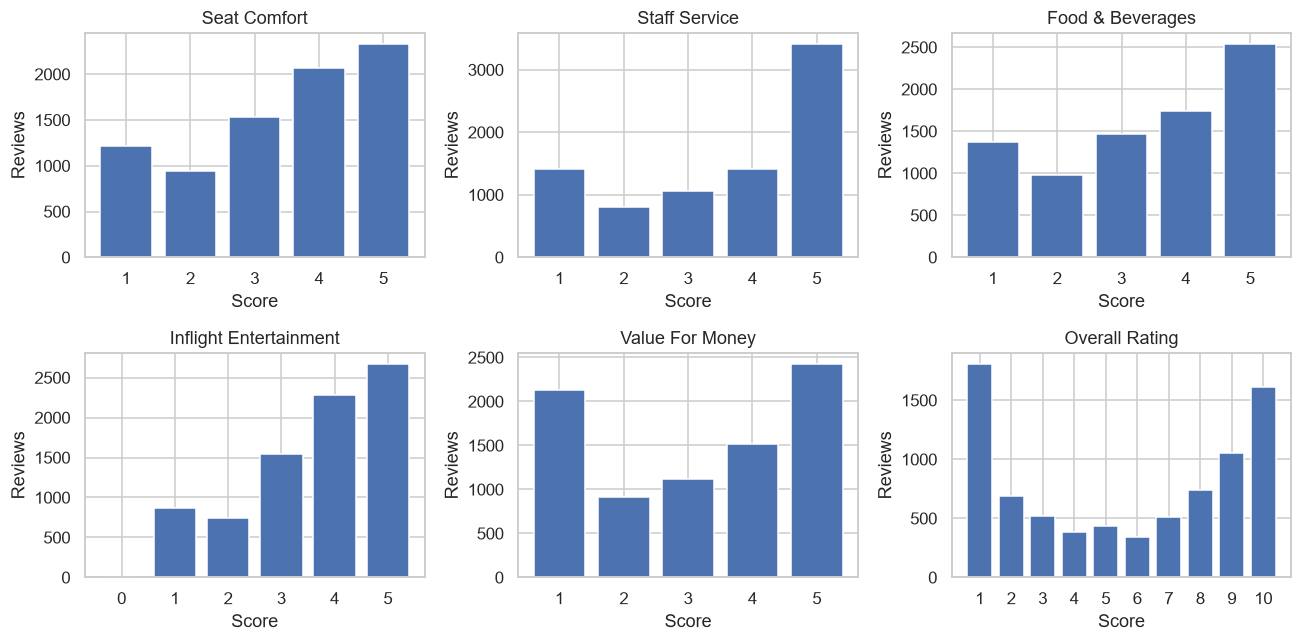

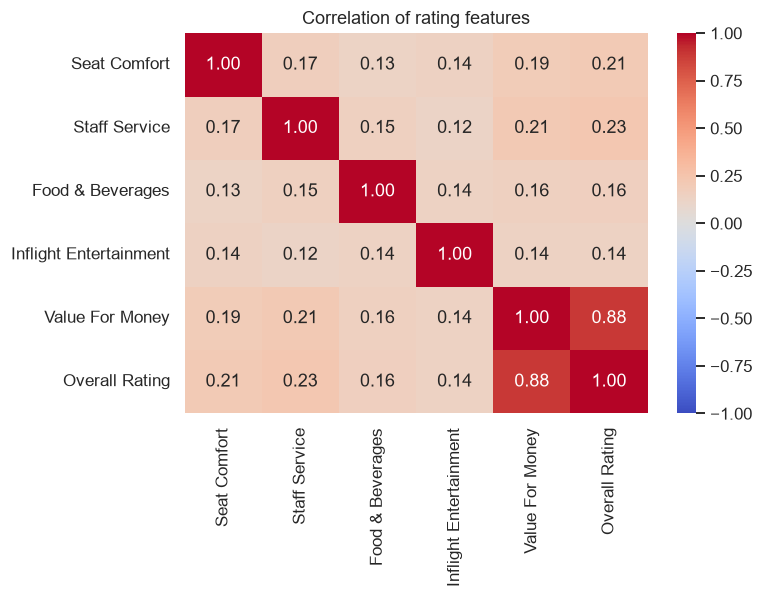

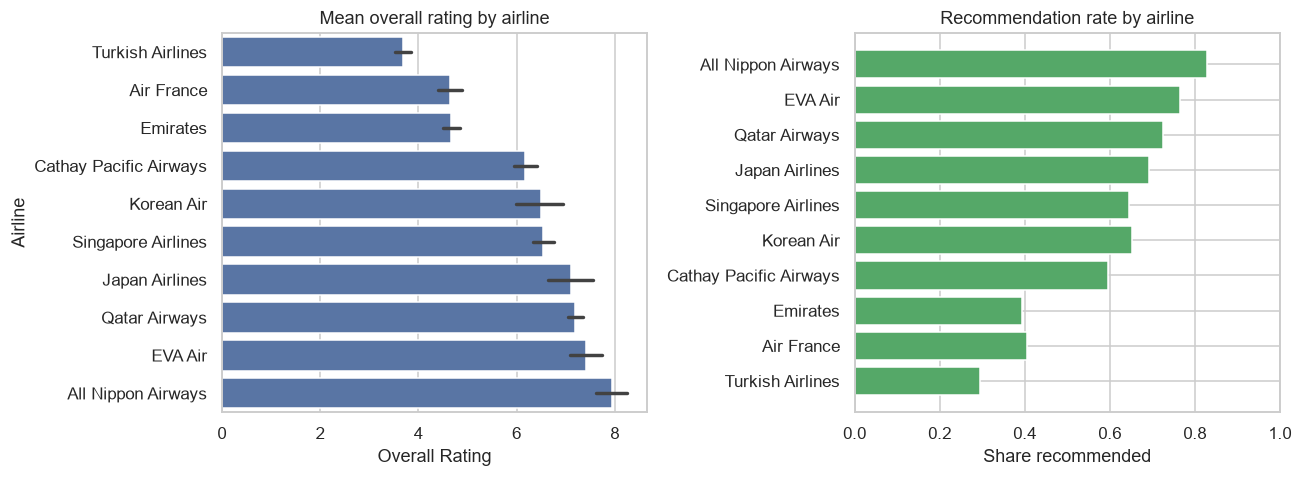

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), RATING_COLS):
    values = raw[col].value_counts().sort_index()
    ax.bar(values.index.astype(str), values.values, color="#4C72B0")
    ax.set_title(col)
    ax.set_xlabel("Score")
    ax.set_ylabel("Reviews")
save_fig(fig, "01_rating_distributions.png")

corr = raw[RATING_COLS].corr()
fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of rating features")
save_fig(fig, "02_correlation_heatmap.png")
RESULTS["corr_value_overall"] = float(corr.loc["Value For Money", "Overall Rating"])

airline_order = raw.groupby("Airline")["Overall Rating"].mean().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(
    data=raw, y="Airline", x="Overall Rating", order=airline_order,
    errorbar=("ci", 95), color="#4C72B0", ax=axes[0],
)
axes[0].set_title("Mean overall rating by airline")
rec = (
    raw.assign(recommend=raw["Recommended"].str.lower().eq("yes"))
    .groupby("Airline")["recommend"].mean()
    .reindex(airline_order)
)
axes[1].barh(rec.index, rec.values, color="#55A868")
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Share recommended")
axes[1].set_title("Recommendation rate by airline")
save_fig(fig, "03_airline_satisfaction.png")

## 4. Data cleaning

Three data issues show up in the raw file:

- `Verified` is almost entirely `True` or `False`, plus three bad entries (`*Unverified*`, `NotVerified`, and one airline-apology sentence stored in the wrong column). Those three rows still have a normal review and normal scores, so the flag is set to `False` and the row is kept.
- `Inflight Entertainment` is a 1–5 score, except one 0. That 0 is outside the scale, so it is treated as missing and replaced with the median of the valid scores.
- One review text is an exact duplicate. One copy is removed.

Survey scores of 1 and 5 (or 10) are real opinions at the end of the scale. The interquartile-range screen is computed to show that those endpoints are not statistical outliers on this bounded scale, and they are kept.

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


,feature,lower,upper,iqr_flags
0,Seat Comfort,-2.50,9.50,0
1,Staff Service,-2.50,9.50,0
2,Food & Beverages,-2.50,9.50,0
3,Inflight Entertainment,0.00,8.00,0
4,Value For Money,-5.00,11.00,0
5,Overall Rating,-8.50,19.50,0
6,Review Length,-515.62,1979.38,427


IQR flags on the six rating columns: 0 (endpoints of a bounded score are kept).


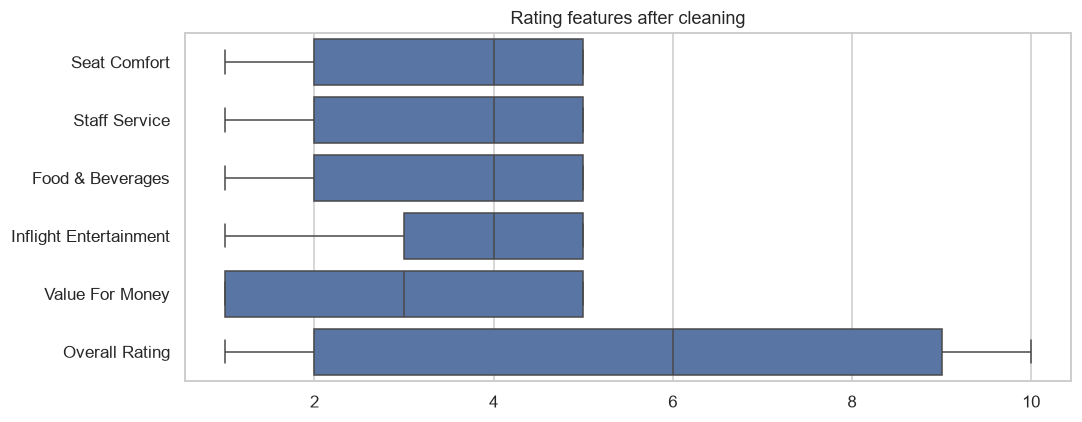

In [5]:
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {"True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False"}
bad_verified = ~df["Verified"].isin(["True", "False"])
RESULTS["n_verified_fixed"] = int(bad_verified.sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
RESULTS["n_ife_zero"] = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median
RESULTS["ife_median_imputed"] = ife_median

RESULTS["n_duplicate_reviews"] = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {RESULTS['n_verified_fixed']}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {RESULTS['n_ife_zero']}")
print(f"Duplicate reviews removed: {RESULTS['n_duplicate_reviews']}")

iqr_rows = []
for col in RATING_COLS + ["Review Length"]:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_flag = int(((df[col] < lo) | (df[col] > hi)).sum())
    iqr_rows.append({"feature": col, "lower": lo, "upper": hi, "iqr_flags": n_flag})
iqr_table = pd.DataFrame(iqr_rows)
display(iqr_table.round(2))
iqr_table.to_csv(OUT / "iqr_screen.csv", index=False)
RESULTS["rating_iqr_flags"] = int(iqr_table.loc[iqr_table["feature"].isin(RATING_COLS), "iqr_flags"].sum())
print(
    "IQR flags on the six rating columns:",
    RESULTS["rating_iqr_flags"],
    "(endpoints of a bounded score are kept).",
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df[RATING_COLS], orient="h", ax=ax, color="#4C72B0")
ax.set_title("Rating features after cleaning")
save_fig(fig, "04_rating_boxplots.png")
RESULTS["n_clean"] = int(len(df))

## 5. Feature engineering

### Why standardisation

K-Means, Ward hierarchical clustering, and DBSCAN all use Euclidean distance. Overall rating runs from 1 to 10 and has a larger standard deviation than the 1–5 service scores. If the raw numbers were used, a one-point gap in overall rating would count the same as a one-point gap in seat comfort, and the wider overall-rating column would dominate the distance.

Standardisation puts every column on a common scale:

\[
z = \frac{x - \mu}{\sigma}
\]

`StandardScaler` estimates \(\mu\) and \(\sigma\) from this dataset (population standard deviation, `ddof=0`). Min-max scaling would also equalise the ranges. Standardisation is used here because the later PCA step and the Euclidean clustering methods are based on variance, and the columns do not share one original unit.

### Which matrix is clustered

| Matrix | What goes in | Role |
| --- | --- | --- |
| `X_main` | 6 standardised ratings | Main space for K-Means, hierarchical clustering, and DBSCAN |
| `X_no_overall` | 5 ratings, overall score removed | Checks how much the overall score drives the groups |
| `X_service` | 4 cabin-service scores only | Drops overall and value-for-money, which are highly correlated |
| `X_mixed_pca` | ratings + one-hot airline, class, traveller type, and binned year, then PCA at 90% variance | Mixed-feature alternative |

`Recommended` stays out of every matrix and is used only to describe the clusters afterwards. `Route` has thousands of distinct values, so it is not one-hot encoded.

Year flown is binned into four periods (2013–2016, 2017–2019, 2020–2021, 2022–2024) and then one-hot encoded. That is the binning step. One-hot encoding is used for airline, cabin class, traveller type, and the year bin.

,feature,mean,std
0,Seat Comfort,3.415,1.397
1,Staff Service,3.570,1.527
2,Food & Beverages,3.384,1.455
3,Inflight Entertainment,3.637,1.309
4,Value For Money,3.149,1.589
5,Overall Rating,5.632,3.523


Worked standardisation for review 0. z = (x - mean) / std


,feature,raw_x,mean,std,z_manual,z_scaler
0,Seat Comfort,4.0,3.4149,1.3969,0.4188,0.4188
1,Staff Service,4.0,3.5699,1.5273,0.2816,0.2816
2,Food & Beverages,4.0,3.3842,1.4554,0.4231,0.4231
3,Inflight Entertainment,4.0,3.6371,1.3089,0.2773,0.2773
4,Value For Money,4.0,3.1486,1.5893,0.5357,0.5357
5,Overall Rating,9.0,5.6324,3.5233,0.9558,0.9558


Max gap between manual z and StandardScaler: 0.0
PCA on the 6 ratings, for the scatter plots:


,PC1,PC2
Seat Comfort,0.292,0.368
Staff Service,0.309,0.318
Food & Beverages,0.249,0.473
Inflight Entertainment,0.228,0.514
Value For Money,0.591,-0.379
Overall Rating,0.597,-0.363


PC1 variance: 36.9%, PC2 variance: 18.4%, together: 55.3%
Mixed one-hot matrix: 28 columns. PCA kept 13 components for 90% variance (actual 91.5%).
Worked PCA score for review 0 (scaled ratings dotted with loadings):
  manual PC1, PC2 = [1.2648 0.0363]
  sklearn PC1, PC2 = [1.2648 0.0363]


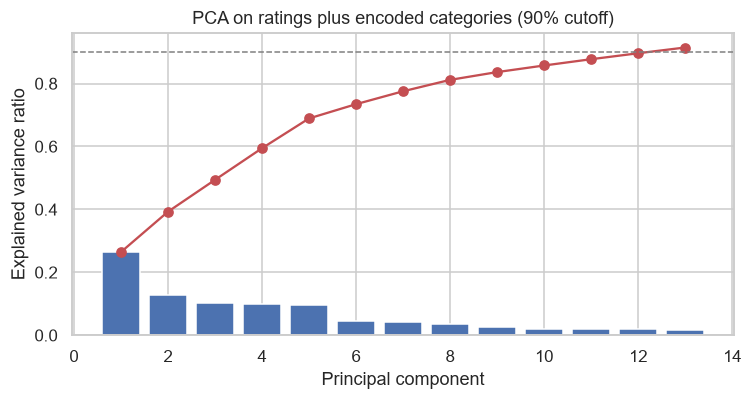

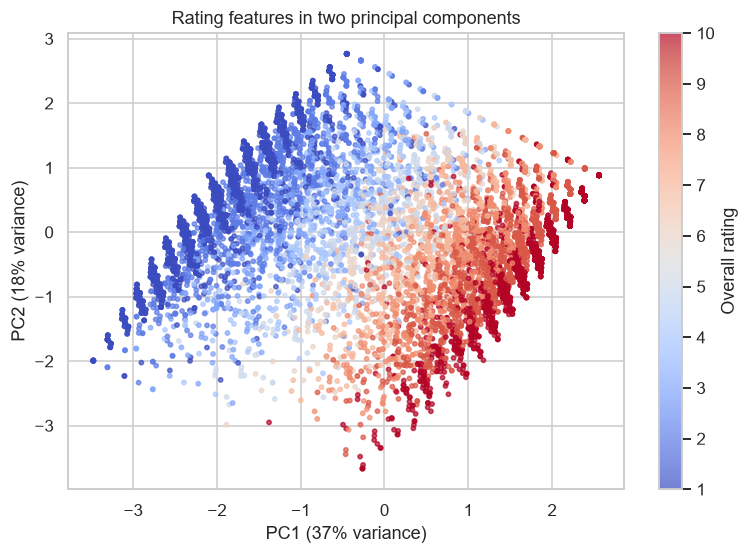

In [6]:
def scale_frame(frame, cols):
    scaler = StandardScaler()
    matrix = scaler.fit_transform(frame[cols])
    return matrix, scaler

X_main, scaler_main = scale_frame(df, RATING_COLS)
X_no_overall, _ = scale_frame(df, [c for c in RATING_COLS if c != "Overall Rating"])
X_service, _ = scale_frame(df, SERVICE_COLS)

scale_table = pd.DataFrame({
    "feature": RATING_COLS,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
})
display(scale_table.round(3))
scale_table.round(6).to_csv(OUT / "standard_scaler_parameters.csv", index=False)

example_raw = df.loc[0, RATING_COLS].to_numpy(dtype=float)
example_z = (example_raw - scaler_main.mean_) / scaler_main.scale_
example_check = scaler_main.transform(df.loc[[0], RATING_COLS])[0]
worked = pd.DataFrame({
    "feature": RATING_COLS,
    "raw_x": example_raw,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
    "z_manual": example_z,
    "z_scaler": example_check,
})
print("Worked standardisation for review 0. z = (x - mean) / std")
display(worked.round(4))
print("Max gap between manual z and StandardScaler:", float(np.max(np.abs(example_z - example_check))))

encoder = OneHotEncoder(sparse_output=False, dtype=np.float64)
cat_cols = ["Airline", "Class", "Type of Traveller", "Year Bin"]
X_cat = encoder.fit_transform(df[cat_cols])
X_mixed = np.hstack([X_main, X_cat])
pca_mixed = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_mixed_pca = pca_mixed.fit_transform(X_mixed)

pca_viz = PCA(n_components=2, random_state=RANDOM_STATE)
XY = pca_viz.fit_transform(X_main)
loadings = pd.DataFrame(
    pca_viz.components_.T, index=RATING_COLS, columns=["PC1", "PC2"]
)
print("PCA on the 6 ratings, for the scatter plots:")
display(loadings.round(3))
print(
    f"PC1 variance: {pca_viz.explained_variance_ratio_[0]:.1%}, "
    f"PC2 variance: {pca_viz.explained_variance_ratio_[1]:.1%}, "
    f"together: {pca_viz.explained_variance_ratio_.sum():.1%}"
)
print(
    f"Mixed one-hot matrix: {X_mixed.shape[1]} columns. "
    f"PCA kept {X_mixed_pca.shape[1]} components for 90% variance "
    f"(actual {pca_mixed.explained_variance_ratio_.sum():.1%})."
)

pc_manual = example_z @ pca_viz.components_.T
pc_sklearn = pca_viz.transform(example_z.reshape(1, -1))[0]
print("Worked PCA score for review 0 (scaled ratings dotted with loadings):")
print(f"  manual PC1, PC2 = {pc_manual.round(4)}")
print(f"  sklearn PC1, PC2 = {pc_sklearn.round(4)}")

RESULTS["pc_variance_2d"] = float(pca_viz.explained_variance_ratio_.sum())
RESULTS["mixed_pca_components"] = int(X_mixed_pca.shape[1])
RESULTS["mixed_pca_variance"] = float(pca_mixed.explained_variance_ratio_.sum())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(np.arange(1, len(pca_mixed.explained_variance_ratio_) + 1), pca_mixed.explained_variance_ratio_, color="#4C72B0")
ax.plot(np.arange(1, len(pca_mixed.explained_variance_ratio_) + 1), np.cumsum(pca_mixed.explained_variance_ratio_), color="#C44E52", marker="o")
ax.axhline(0.90, color="gray", ls="--", lw=1)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("PCA on ratings plus encoded categories (90% cutoff)")
save_fig(fig, "05_pca_scree.png")

fig, ax = plt.subplots(figsize=(7.2, 5.2))
sc = ax.scatter(XY[:, 0], XY[:, 1], c=df["Overall Rating"], cmap="coolwarm", s=8, alpha=0.7)
fig.colorbar(sc, ax=ax, label="Overall rating")
ax.set_xlabel(f"PC1 ({pca_viz.explained_variance_ratio_[0]:.0%} variance)")
ax.set_ylabel(f"PC2 ({pca_viz.explained_variance_ratio_[1]:.0%} variance)")
ax.set_title("Rating features in two principal components")
save_fig(fig, "06_pca_scatter_rating.png")
loadings.round(4).to_csv(OUT / "pca_loadings.csv")

## 6. K-Means

K-Means searches for \(K\) centres and assigns every review to the nearest centre. The objective it reduces is the within-cluster sum of squares:

\[
J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2
\]

Each fit alternates two steps: assign each point to the closest centre, then move each centre to the mean of its points. The algorithm stops when the assignments settle. It assumes clusters are roughly spherical and of similar size, and every point is forced into a cluster.

`K` is chosen from the silhouette score for \(K = 2, \ldots, 10\). The inertia curve (the elbow plot) is shown beside it. Silhouette is the selection rule because it is the shared metric later used for hierarchical clustering and DBSCAN. For a point \(i\):

\[
s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}
\]

where \(a(i)\) is the mean distance to other points in the same cluster and \(b(i)\) is the mean distance to the nearest other cluster. The score ranges from −1 to 1. Values near 1 mean a tight, separated cluster. Values near 0 mean clusters that overlap.

,k,inertia,silhouette
0,2,34573.5774,0.2708
1,3,30797.9174,0.2163
2,4,27570.7924,0.1913
3,5,25353.3927,0.1952
4,6,23276.8173,0.1965
5,7,21614.2421,0.2007
6,8,20277.6895,0.1978
7,9,19011.2074,0.1978
8,10,18018.5410,0.2000


Selected K = 2 with silhouette 0.2708.
Next best K = 3 with silhouette 0.2163.


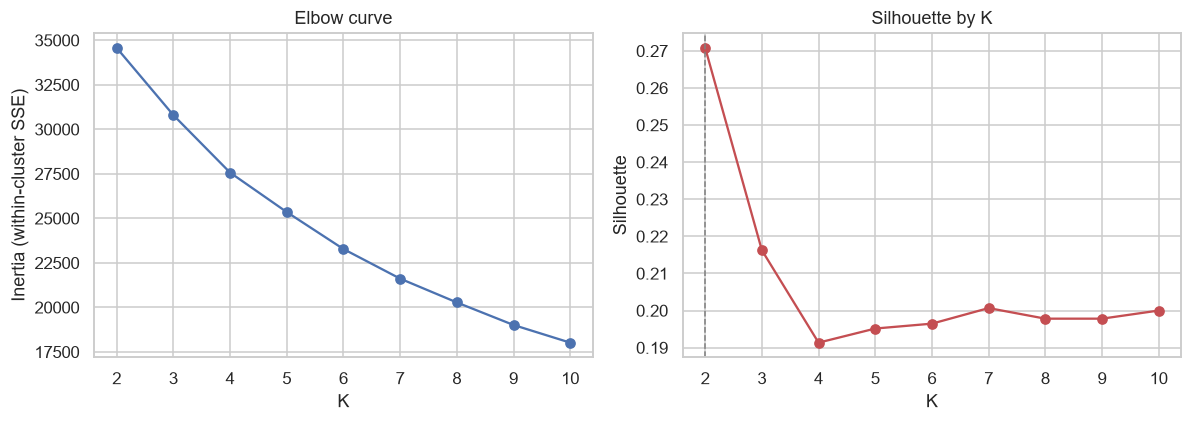

Final inertia J = 34,573.6
Cluster centres converted back to the original rating scales:


,cluster,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,n
0,0,3.03,3.12,3.07,3.41,1.64,2.21,3670
1,1,3.73,3.94,3.65,3.83,4.40,8.47,4428


In [7]:
k_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_main)
    k_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_safe(X_main, labels),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))
k_table.to_csv(OUT / "kmeans_k_selection.csv", index=False)

best_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
best_k_sil = float(k_table["silhouette"].max())
second = k_table.sort_values("silhouette", ascending=False).iloc[1]
RESULTS["kmeans_k"] = best_k
RESULTS["kmeans_silhouette"] = best_k_sil
print(f"Selected K = {best_k} with silhouette {best_k_sil:.4f}.")
print(f"Next best K = {int(second['k'])} with silhouette {second['silhouette']:.4f}.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o", color="#4C72B0")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow curve")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color="#C44E52")
axes[1].axvline(best_k, color="gray", ls="--", lw=1)
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Silhouette by K")
save_fig(fig, "07_kmeans_selection.png")

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
df["kmeans"] = kmeans.fit_predict(X_main)
centers = pd.DataFrame(
    scaler_main.inverse_transform(kmeans.cluster_centers_),
    columns=RATING_COLS,
)
centers.insert(0, "cluster", centers.index)
centers["n"] = pd.Series(df["kmeans"]).value_counts().sort_index().to_numpy()
print(f"Final inertia J = {kmeans.inertia_:,.1f}")
print("Cluster centres converted back to the original rating scales:")
display(centers.round(2))
centers.round(3).to_csv(OUT / "kmeans_centers.csv", index=False)
RESULTS["kmeans_inertia"] = float(kmeans.inertia_)

K-Means cluster profile (means of the original scores):


,cluster,n,pct,recommend_rate,top_class,top_airline,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,name
0,0,3670,45.32,0.064,Economy Class,Turkish Airlines,3.032,3.121,3.071,3.407,1.638,2.205,Low satisfaction
1,1,4428,54.68,0.915,Economy Class,Qatar Airways,3.732,3.942,3.644,3.828,4.400,8.473,High satisfaction


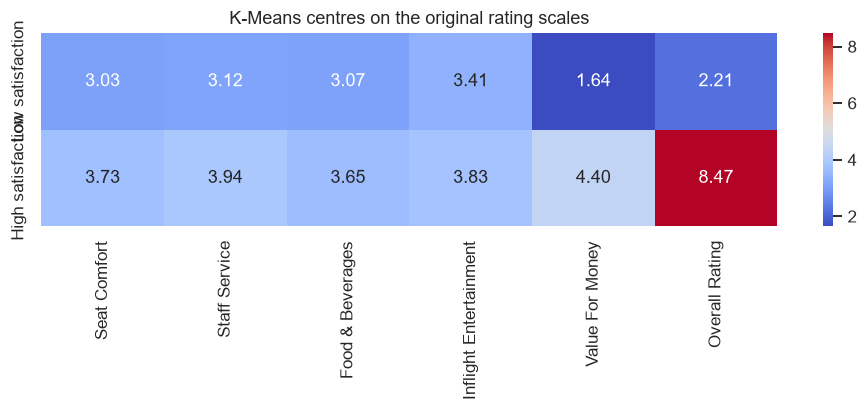

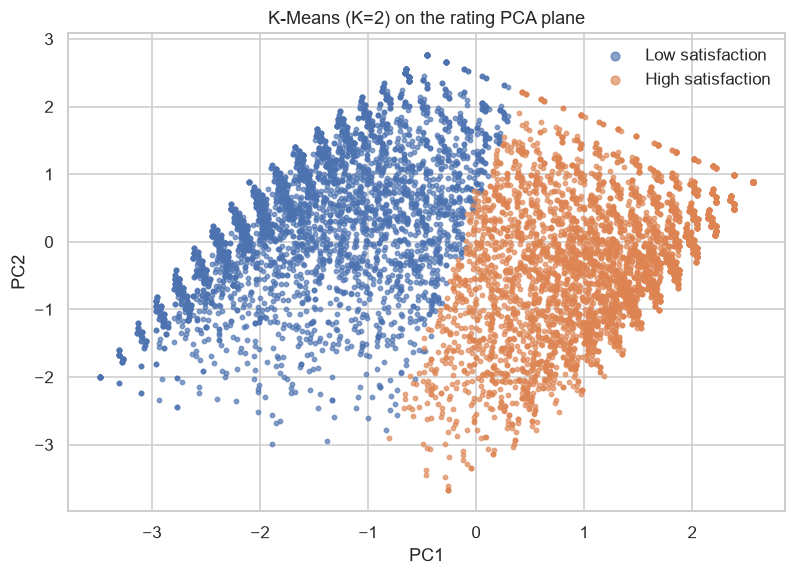

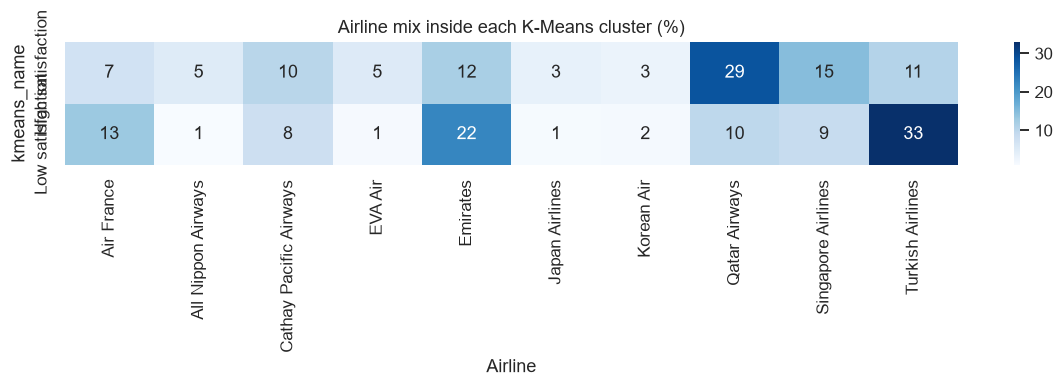

In [8]:
def name_clusters(frame, label_col, score_col="Overall Rating"):
    # Name groups from low to high mean overall rating. Noise (-1) stays Noise.
    means = frame.loc[frame[label_col] != -1].groupby(label_col)[score_col].mean().sort_values()
    labels = list(means.index)
    if len(labels) == 2:
        pretty = ["Low satisfaction", "High satisfaction"]
    elif len(labels) == 3:
        pretty = ["Low satisfaction", "Mixed satisfaction", "High satisfaction"]
    else:
        pretty = [f"Segment {i} (low to high)" for i in range(1, len(labels) + 1)]
    mapping = {lab: pretty[i] for i, lab in enumerate(labels)}
    if (frame[label_col] == -1).any():
        mapping[-1] = "Noise"
    return mapping


def profile_clusters(frame, label_col):
    rows = []
    for lab, g in frame.groupby(label_col):
        row = {
            "cluster": lab,
            "n": len(g),
            "pct": 100 * len(g) / len(frame),
            "recommend_rate": g["Recommended"].str.lower().eq("yes").mean(),
            "top_class": g["Class"].value_counts().index[0],
            "top_airline": g["Airline"].value_counts().index[0],
        }
        for col in RATING_COLS:
            row[col] = g[col].mean()
        rows.append(row)
    out = pd.DataFrame(rows)
    out["name"] = out["cluster"].map(name_clusters(frame, label_col))
    return out.sort_values("Overall Rating")


k_profile = profile_clusters(df, "kmeans")
k_names = name_clusters(df, "kmeans")
df["kmeans_name"] = df["kmeans"].map(k_names)
print("K-Means cluster profile (means of the original scores):")
display(k_profile.round(3))
k_profile.round(3).to_csv(OUT / "kmeans_profile.csv", index=False)

heat = centers.set_index("cluster")[RATING_COLS]
heat.index = [k_names[i] for i in heat.index]
fig, ax = plt.subplots(figsize=(9, 3.2 + 0.35 * len(heat)))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("K-Means centres on the original rating scales")
save_fig(fig, "08_kmeans_centers.png")

fig, ax = plt.subplots(figsize=(7.4, 5.4))
for lab, g_idx in df.groupby("kmeans").groups.items():
    ax.scatter(XY[list(g_idx), 0], XY[list(g_idx), 1], s=8, alpha=0.65, label=k_names[lab])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"K-Means (K={best_k}) on the rating PCA plane")
ax.legend(markerscale=2, frameon=False)
save_fig(fig, "09_kmeans_pca.png")

airline_mix = pd.crosstab(df["kmeans_name"], df["Airline"], normalize="index")
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(airline_mix * 100, annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set_title("Airline mix inside each K-Means cluster (%)")
save_fig(fig, "10_kmeans_airline_mix.png")

## 7. Hierarchical clustering

Hierarchical clustering merges reviews from the bottom up. Each review starts as its own cluster. At every step the closest pair of clusters is merged, until one cluster remains. The dendrogram draws that sequence. The height of a join is the distance between the two clusters that were merged.

Three linkage rules are compared. Each defines the distance between two clusters \(A\) and \(B\):

- **Average:** the mean of all pairwise distances between a point in \(A\) and a point in \(B\).
- **Complete:** the largest pairwise distance between \(A\) and \(B\) (the two farthest points).
- **Ward:** the increase in within-cluster sum of squares if \(A\) and \(B\) were merged. Ward only applies to Euclidean distance and tends to form compact clusters, which is the same geometry K-Means prefers.

The tree is cut with `fcluster` so that it yields a flat set of \(K\) clusters. \(K\) from 2 to 8 is scored with the silhouette coefficient on the same standardised ratings. The cophenetic correlation is also reported: it measures how faithfully the whole tree preserves the original pairwise distances (closer to 1 is a better tree), which is separate from the quality of one flat cut.

complete linkage requested K=2, but fcluster returned 1 cluster(s). Tied merge heights make that cut undefined, so silhouette is left blank.


Cophenetic correlation (tree vs original distances):


,cophenetic
ward,0.5515
complete,0.5502
average,0.6180


Silhouette of the flat cut:


,ward,complete,average
2,0.2469,NaN,0.2471
3,0.1987,0.1700,0.1858
4,0.1576,0.1387,0.1712
5,0.1530,0.1309,0.1411
6,0.1323,0.1212,0.1372
7,0.1326,0.1156,0.1397
8,0.1381,0.1227,0.1316


Selected cut: average linkage, K = 2, silhouette 0.2471.
Hierarchical cluster profile:


,cluster,n,pct,recommend_rate,top_class,top_airline,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,name
0,1,3707,45.777,0.086,Economy Class,Turkish Airlines,3.216,3.175,3.143,3.462,1.691,2.282,Low satisfaction
1,2,4391,54.223,0.903,Economy Class,Qatar Airways,3.583,3.903,3.588,3.785,4.379,8.461,High satisfaction


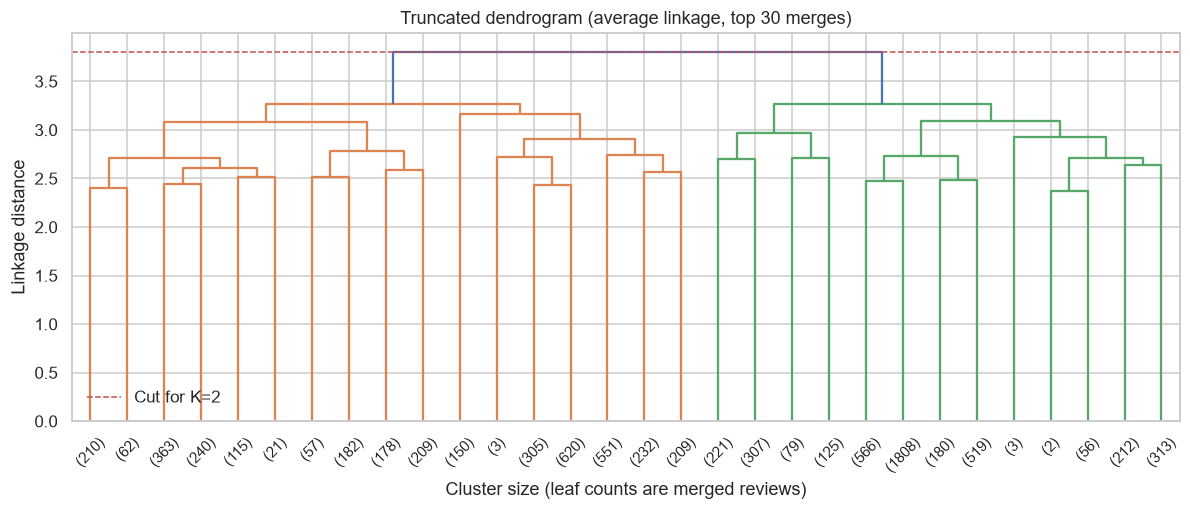

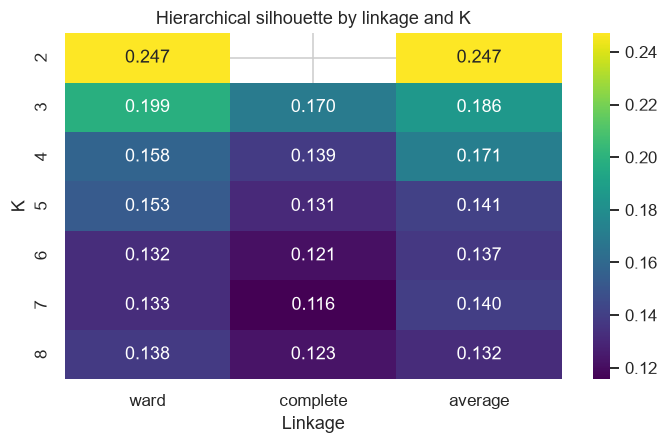

In [9]:
linkages = {}
cophenetic_scores = {}
distance_condensed = pdist(X_main, metric="euclidean")
for method in ["ward", "complete", "average"]:
    Z = linkage(X_main, method=method, metric="euclidean")
    linkages[method] = Z
    cophenetic_scores[method] = float(cophenet(Z, distance_condensed)[0])

sil_link = pd.DataFrame(index=range(2, 9), columns=["ward", "complete", "average"], dtype=float)
for method, Z in linkages.items():
    for k in sil_link.index:
        labels = fcluster(Z, t=k, criterion="maxclust")
        n_found = len(np.unique(labels))
        if n_found != k:
            sil_link.loc[k, method] = np.nan
            print(
                f"{method} linkage requested K={k}, but fcluster returned {n_found} "
                "cluster(s). Tied merge heights make that cut undefined, so silhouette is left blank."
            )
        else:
            sil_link.loc[k, method] = silhouette_safe(X_main, labels)

print("Cophenetic correlation (tree vs original distances):")
display(pd.Series(cophenetic_scores, name="cophenetic").round(4).to_frame())
print("Silhouette of the flat cut:")
display(sil_link.round(4))
sil_link.to_csv(OUT / "hierarchical_silhouette.csv")

best_pos = np.unravel_index(np.nanargmax(sil_link.to_numpy()), sil_link.shape)
hier_k = int(sil_link.index[best_pos[0]])
hier_method = str(sil_link.columns[best_pos[1]])
hier_sil = float(sil_link.loc[hier_k, hier_method])
RESULTS["hier_k"] = hier_k
RESULTS["hier_method"] = hier_method
RESULTS["hier_silhouette"] = hier_sil
RESULTS["cophenetic"] = cophenetic_scores
print(f"Selected cut: {hier_method} linkage, K = {hier_k}, silhouette {hier_sil:.4f}.")

Z_best = linkages[hier_method]
df["hierarchical"] = fcluster(Z_best, t=hier_k, criterion="maxclust")
h_profile = profile_clusters(df, "hierarchical")
h_names = name_clusters(df, "hierarchical")
df["hierarchical_name"] = df["hierarchical"].map(h_names)
print("Hierarchical cluster profile:")
display(h_profile.round(3))
h_profile.round(3).to_csv(OUT / "hierarchical_profile.csv", index=False)

color_threshold = Z_best[-(hier_k - 1), 2]
fig, ax = plt.subplots(figsize=(11, 4.8))
dendrogram(
    Z_best, truncate_mode="lastp", p=30, color_threshold=color_threshold,
    above_threshold_color="#4C72B0", ax=ax,
)
ax.axhline(color_threshold, color="#C44E52", ls="--", lw=1, label=f"Cut for K={hier_k}")
ax.set_title(f"Truncated dendrogram ({hier_method} linkage, top 30 merges)")
ax.set_xlabel("Cluster size (leaf counts are merged reviews)")
ax.set_ylabel("Linkage distance")
ax.legend(frameon=False)
save_fig(fig, "11_dendrogram.png")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(sil_link.astype(float), annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_xlabel("Linkage")
ax.set_ylabel("K")
ax.set_title("Hierarchical silhouette by linkage and K")
save_fig(fig, "12_linkage_silhouette.png")

## 8. DBSCAN

DBSCAN groups points that sit in a dense region and leaves isolated points as noise. Two parameters define density:

- \(\varepsilon\) (`eps`): the neighbourhood radius.
- `min_samples`: how many points must fall inside that radius for a point to count as a core point.

A point is a **core** point when at least `min_samples` points (including itself) lie within \(\varepsilon\). A **border** point is inside a core point's neighbourhood but is not itself a core. A **noise** point is neither. Clusters are chains of core points whose neighbourhoods overlap, plus their border points. Unlike K-Means, DBSCAN can leave points unclustered and can find non-spherical groups. It struggles when the cloud has no empty gap between groups, because a single \(\varepsilon\) then either joins everything or marks too many points as noise.

`min_samples` is tried at 8, 12, and 16 (around twice the number of rating features). For each choice, a k-distance curve sorts each review's distance to its `min_samples`-th neighbour. The curve's knee, estimated as the point farthest from the line between the first and last distances, is a candidate \(\varepsilon\). A grid around that knee is then scored. Silhouette is computed on the non-noise points only. A setting is eligible when it finds 2 to 8 clusters and marks at most 35% of reviews as noise.

Highest-silhouette DBSCAN settings:


,min_samples,eps,knee_eps,n_clusters,noise_frac,silhouette
10,12,0.877,1.0320,5,0.0879,-0.0819
2,8,0.845,0.9945,4,0.0752,-0.1750
18,16,0.930,1.0941,5,0.1071,-0.1856
17,16,0.766,1.0941,6,0.2436,-0.2575
0,8,0.547,0.9945,132,0.7480,NaN
1,8,0.696,0.9945,70,0.2330,NaN
3,8,0.994,0.9945,1,0.0061,NaN
4,8,1.144,0.9945,1,0.0014,NaN


Selected DBSCAN: eps=0.877, min_samples=12, clusters=5, noise=8.8%, silhouette=-0.0819.
DBSCAN profile (noise included):


,cluster,n,pct,recommend_rate,top_class,top_airline,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,name
3,2,10,0.123,0.300,Economy Class,Turkish Airlines,2.100,5.000,4.800,1.000,3.100,4.500,Segment 1 (low to high)
0,-1,712,8.792,0.500,Economy Class,Turkish Airlines,2.663,2.768,2.718,2.587,3.424,5.449,Noise
1,0,7354,90.813,0.531,Economy Class,Qatar Airways,3.494,3.650,3.452,3.741,3.119,5.644,Segment 2 (low to high)
4,3,10,0.123,0.800,Economy Class,Emirates,1.300,1.100,1.900,5.000,3.800,7.100,Segment 3 (low to high)
5,4,5,0.062,1.000,Economy Class,Cathay Pacific Airways,5.000,3.400,1.200,1.000,4.000,8.600,Segment 4 (low to high)
2,1,7,0.086,1.000,Economy Class,Emirates,1.000,2.286,1.429,4.857,5.000,9.429,Segment 5 (low to high)


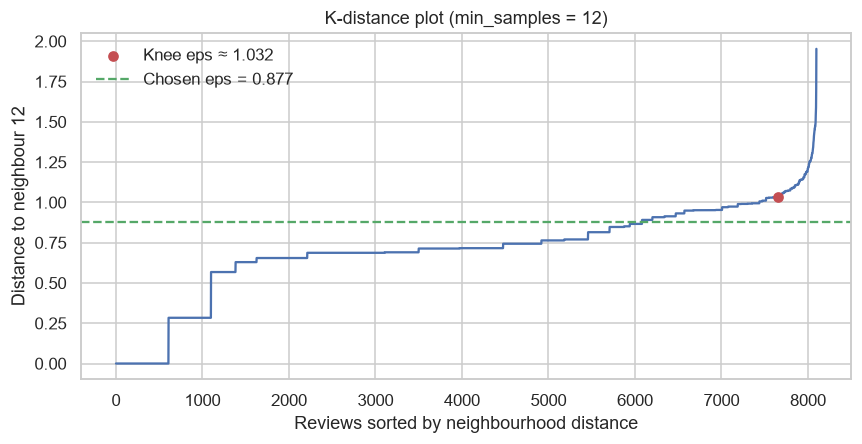

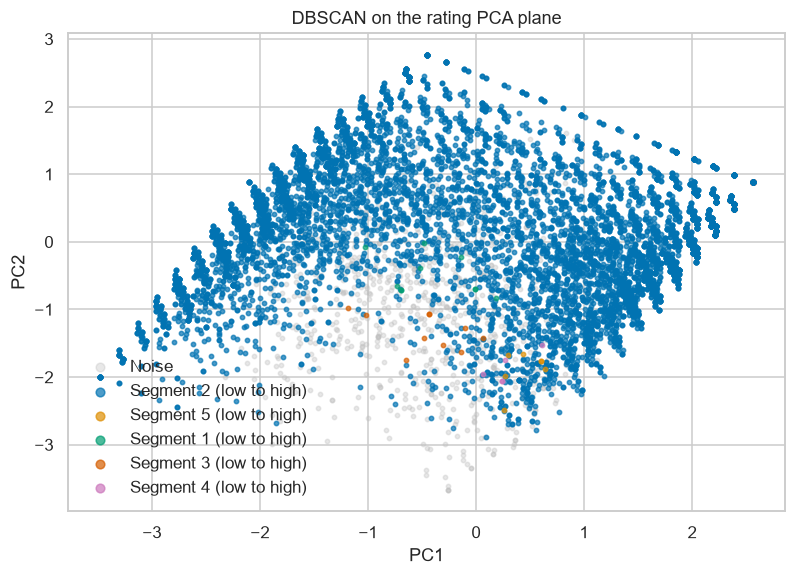

In [10]:
def knee_epsilon(sorted_dist):
    y = np.asarray(sorted_dist, dtype=float)
    x = np.linspace(0.0, 1.0, len(y))
    y_n = (y - y.min()) / (y.max() - y.min() + 1e-12)
    line = np.array([1.0, y_n[-1] - y_n[0]])
    vecs = np.column_stack([x, y_n - y_n[0]])
    cross = np.abs(line[0] * vecs[:, 1] - line[1] * vecs[:, 0])
    idx = int(np.argmax(cross))
    return float(y[idx]), idx


db_rows = []
kdist_for_plot = {}
for min_samples in [8, 12, 16]:
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X_main)
    dists = np.sort(nn.kneighbors(X_main)[0][:, -1])
    knee, knee_idx = knee_epsilon(dists)
    kdist_for_plot[min_samples] = (dists, knee, knee_idx)
    eps_grid = np.unique(np.round(np.linspace(knee * 0.55, knee * 1.6, 8), 3))
    for eps in eps_grid:
        labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X_main)
        n_clusters = len(set(labels) - {-1})
        noise = float(np.mean(labels == -1))
        sil = silhouette_safe(X_main, labels) if 2 <= n_clusters <= 8 and noise <= 0.50 else np.nan
        db_rows.append({
            "min_samples": min_samples,
            "eps": float(eps),
            "knee_eps": knee,
            "n_clusters": n_clusters,
            "noise_frac": noise,
            "silhouette": sil,
        })

db_table = pd.DataFrame(db_rows)
eligible = db_table[
    db_table["silhouette"].notna()
    & (db_table["n_clusters"].between(2, 8))
    & (db_table["noise_frac"] <= 0.35)
].copy()
if eligible.empty:
    eligible = db_table[db_table["silhouette"].notna()].copy()
print("Highest-silhouette DBSCAN settings:")
display(db_table.sort_values("silhouette", ascending=False).head(8).round(4))
db_table.to_csv(OUT / "dbscan_grid.csv", index=False)

best_db = eligible.sort_values(["silhouette", "noise_frac"], ascending=[False, True]).iloc[0]
db_eps = float(best_db["eps"])
db_min = int(best_db["min_samples"])
db_model = DBSCAN(eps=db_eps, min_samples=db_min)
df["dbscan"] = db_model.fit_predict(X_main)
db_sil = silhouette_safe(X_main, df["dbscan"])
db_noise = float((df["dbscan"] == -1).mean())
db_n = len(set(df["dbscan"]) - {-1})
RESULTS["dbscan_eps"] = db_eps
RESULTS["dbscan_min_samples"] = db_min
RESULTS["dbscan_clusters"] = db_n
RESULTS["dbscan_noise"] = db_noise
RESULTS["dbscan_silhouette"] = float(db_sil) if np.isfinite(db_sil) else None
print(
    f"Selected DBSCAN: eps={db_eps:.3f}, min_samples={db_min}, "
    f"clusters={db_n}, noise={db_noise:.1%}, silhouette={db_sil:.4f}."
)

d_profile = profile_clusters(df, "dbscan")
d_names = name_clusters(df, "dbscan")
df["dbscan_name"] = df["dbscan"].map(d_names)
print("DBSCAN profile (noise included):")
display(d_profile.round(3))
d_profile.round(3).to_csv(OUT / "dbscan_profile.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
dists, knee, knee_idx = kdist_for_plot[db_min]
ax.plot(dists, color="#4C72B0")
ax.scatter([knee_idx], [knee], color="#C44E52", zorder=3, label=f"Knee eps ≈ {knee:.3f}")
ax.axhline(db_eps, color="#55A868", ls="--", label=f"Chosen eps = {db_eps:.3f}")
ax.set_xlabel("Reviews sorted by neighbourhood distance")
ax.set_ylabel(f"Distance to neighbour {db_min}")
ax.set_title(f"K-distance plot (min_samples = {db_min})")
ax.legend(frameon=False)
save_fig(fig, "13_kdistance.png")

fig, ax = plt.subplots(figsize=(7.4, 5.4))
palette = sns.color_palette("colorblind", n_colors=max(db_n, 1))
color_i = 0
for lab in sorted(df["dbscan"].unique()):
    m = df["dbscan"].to_numpy() == lab
    if lab == -1:
        ax.scatter(XY[m, 0], XY[m, 1], s=8, alpha=0.35, color="0.75", label=d_names[lab])
    else:
        ax.scatter(
            XY[m, 0], XY[m, 1], s=8, alpha=0.7,
            color=palette[color_i % len(palette)], label=d_names[lab],
        )
        color_i += 1
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("DBSCAN on the rating PCA plane")
ax.legend(markerscale=2, frameon=False)
save_fig(fig, "14_dbscan_pca.png")

## 9. Model comparison and the effect of the feature set

All three algorithms are scored with the silhouette coefficient on the same six standardised ratings. The feature-set test refits K-Means on the alternative matrices and again chooses \(K\) by silhouette. A higher score means the partition is tighter in that feature space. It does not by itself mean the groups are more useful; the profile tables (mean scores and recommendation rate) are what show whether a cluster is a recognisable passenger segment.

Clustering models on the main rating space:


,model,feature_space,parameters,clusters,noise_pct,silhouette
0,K-Means,6 standardised ratings,K=2,2,0.0000,0.2708
1,Hierarchical,6 standardised ratings,"average, K=2",2,0.0000,0.2471
2,DBSCAN,6 standardised ratings,"eps=0.877, min_samples=12",5,8.7923,-0.0819


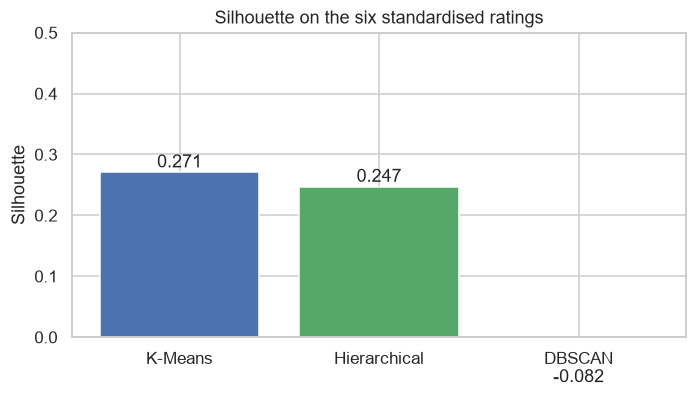

K-Means silhouette when the feature set changes (K re-selected in each space):


,feature_space,best_k,silhouette
0,6 ratings (main),2,0.2708
1,"5 ratings, no overall",2,0.2244
2,4 service scores only,8,0.2610
3,Mixed features + PCA 90%,2,0.2085


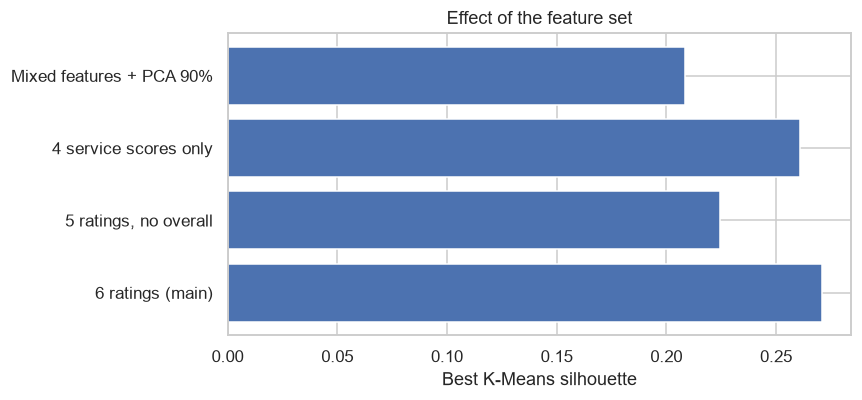

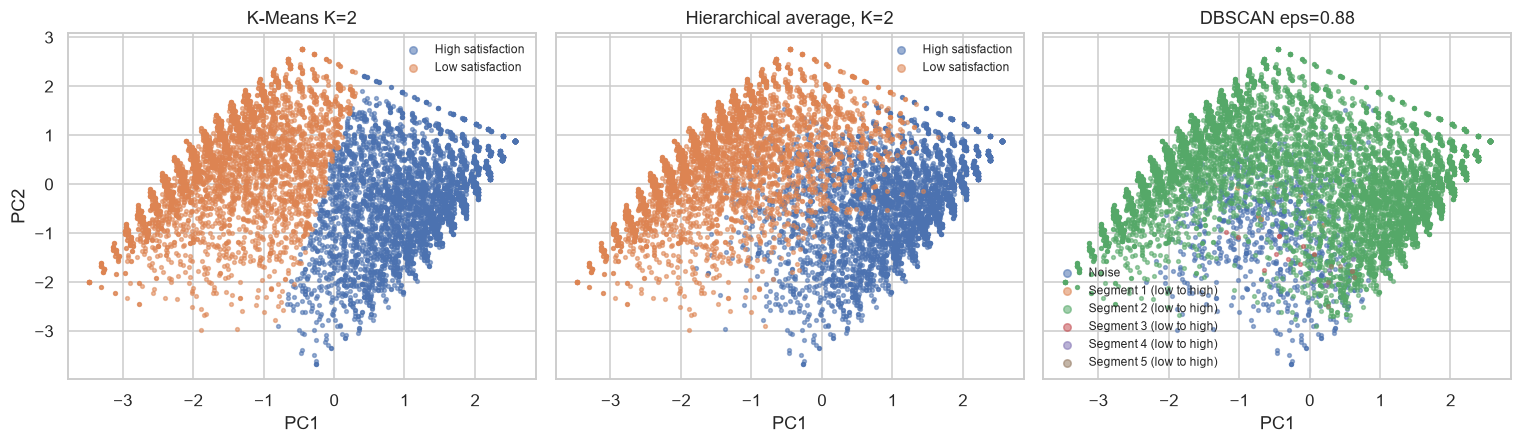

In [11]:
comparison = pd.DataFrame([
    {
        "model": "K-Means",
        "feature_space": "6 standardised ratings",
        "parameters": f"K={RESULTS['kmeans_k']}",
        "clusters": RESULTS["kmeans_k"],
        "noise_pct": 0.0,
        "silhouette": RESULTS["kmeans_silhouette"],
    },
    {
        "model": "Hierarchical",
        "feature_space": "6 standardised ratings",
        "parameters": f"{RESULTS['hier_method']}, K={RESULTS['hier_k']}",
        "clusters": RESULTS["hier_k"],
        "noise_pct": 0.0,
        "silhouette": RESULTS["hier_silhouette"],
    },
    {
        "model": "DBSCAN",
        "feature_space": "6 standardised ratings",
        "parameters": f"eps={RESULTS['dbscan_eps']:.3f}, min_samples={RESULTS['dbscan_min_samples']}",
        "clusters": RESULTS["dbscan_clusters"],
        "noise_pct": 100 * RESULTS["dbscan_noise"],
        "silhouette": RESULTS["dbscan_silhouette"],
    },
])
print("Clustering models on the main rating space:")
display(comparison.round(4))
comparison.to_csv(OUT / "model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
colors = ["#4C72B0", "#55A868", "#C44E52"]
ax.bar(comparison["model"], comparison["silhouette"], color=colors)
ax.set_ylim(0, max(0.5, comparison["silhouette"].max() + 0.05))
ax.set_ylabel("Silhouette")
ax.set_title("Silhouette on the six standardised ratings")
for i, v in enumerate(comparison["silhouette"]):
    ax.text(i, v + 0.008, f"{v:.3f}", ha="center")
save_fig(fig, "15_model_comparison.png")

feature_sets = {
    "6 ratings (main)": X_main,
    "5 ratings, no overall": X_no_overall,
    "4 service scores only": X_service,
    "Mixed features + PCA 90%": X_mixed_pca,
}
feat_rows = []
for name, matrix in feature_sets.items():
    best = None
    for k in range(2, 9):
        labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(matrix)
        sil = silhouette_safe(matrix, labels)
        if best is None or sil > best["silhouette"]:
            best = {"feature_space": name, "best_k": k, "silhouette": sil}
    feat_rows.append(best)
feat_table = pd.DataFrame(feat_rows)
print("K-Means silhouette when the feature set changes (K re-selected in each space):")
display(feat_table.round(4))
feat_table.to_csv(OUT / "feature_set_comparison.csv", index=False)
RESULTS["feature_set_table"] = feat_table

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(feat_table["feature_space"], feat_table["silhouette"], color="#4C72B0")
ax.set_xlabel("Best K-Means silhouette")
ax.set_title("Effect of the feature set")
save_fig(fig, "16_feature_set_comparison.png")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
panel = [
    ("kmeans_name", f"K-Means K={best_k}"),
    ("hierarchical_name", f"Hierarchical {hier_method}, K={hier_k}"),
    ("dbscan_name", f"DBSCAN eps={db_eps:.2f}"),
]
for ax, (col, title) in zip(axes, panel):
    for lab, g_idx in df.groupby(col).groups.items():
        ax.scatter(XY[list(g_idx), 0], XY[list(g_idx), 1], s=6, alpha=0.55, label=lab)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.legend(markerscale=2, fontsize=8, frameon=False)
axes[0].set_ylabel("PC2")
save_fig(fig, "17_three_models_pca.png")

## 10. Text vectorisation and cosine similarity

The text field is `Reviews`. Cleaning lowercases the text, drops URLs and punctuation, and collapses whitespace. The corpus vectorisers then drop English stop-words.

### Worked example, then the full corpus

Bag of Words represents a review by how often each vocabulary word appears. TF-IDF rescales those counts so words that appear in almost every review count for less. With \(n\) reviews and document frequency \(\mathrm{df}(t)\), scikit-learn's smoothed IDF is

\[
\mathrm{idf}(t) = \ln\left(\frac{1+n}{1+\mathrm{df}(t)}\right) + 1
\]

\[
\mathrm{tfidf}(t, d) = \mathrm{tf}(t, d) \times \mathrm{idf}(t)
\]

Each review vector is then divided by its Euclidean length (L2 normalisation). Cosine similarity between two reviews is

\[
\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}
\]

After L2 normalisation the denominators are 1, so the cosine equals the dot product. The toy corpus below is computed by hand with these formulas and checked against `TfidfVectorizer`. The full corpus uses the same definitions.

In [12]:
def clean_text(text):
    text = text.replace("\xa0", " ").lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["review_clean"] = df["Reviews"].map(clean_text)
empty_text = int((df["review_clean"] == "").sum())
RESULTS["empty_text"] = empty_text
print(f"Empty reviews after cleaning: {empty_text}")
print("Example cleaned review:")
print(df.loc[0, "review_clean"][:400])

toy_docs = [
    "good food good service flight",
    "poor food rude service flight",
    "good food good crew flight",
]
toy_count = CountVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
tf_matrix = toy_count.fit_transform(toy_docs).toarray().astype(float)
vocab = np.array(toy_count.get_feature_names_out())
n_docs = tf_matrix.shape[0]
df_t = (tf_matrix > 0).sum(axis=0)
idf = np.log((1 + n_docs) / (1 + df_t)) + 1
tfidf_raw = tf_matrix * idf
tfidf_norm = tfidf_raw / np.linalg.norm(tfidf_raw, axis=1, keepdims=True)

toy_tf = pd.DataFrame(tf_matrix, index=["doc1", "doc2", "doc3"], columns=vocab)
toy_idf = pd.DataFrame({"df": df_t, "idf": idf}, index=vocab)
print("Term counts:")
display(toy_tf.astype(int))
print("Document frequency and idf = ln((1+n)/(1+df)) + 1, with n = 3:")
display(toy_idf.round(4))
print("L2-normalised TF-IDF:")
display(pd.DataFrame(tfidf_norm, index=toy_tf.index, columns=vocab).round(4))

sklearn_tfidf = TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", norm="l2", smooth_idf=True)
sklearn_matrix = sklearn_tfidf.fit_transform(toy_docs).toarray()
sklearn_terms = sklearn_tfidf.get_feature_names_out()
sklearn_matrix = sklearn_matrix[:, [list(sklearn_terms).index(term) for term in vocab]]
print("Max absolute gap versus TfidfVectorizer:", float(np.max(np.abs(tfidf_norm - sklearn_matrix))))

def cosine_pair(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

pairs = [("doc1", "doc2", 0, 1), ("doc1", "doc3", 0, 2), ("doc2", "doc3", 1, 2)]
print("Cosine from the L2-normalised vectors (equals the dot product):")
for name_a, name_b, i, j in pairs:
    dot = float(np.dot(tfidf_norm[i], tfidf_norm[j]))
    print(f"  cos({name_a}, {name_b}) = {dot:.4f}  | manual formula {cosine_pair(tfidf_raw[i], tfidf_raw[j]):.4f}")
RESULTS["toy_cos_12"] = float(np.dot(tfidf_norm[0], tfidf_norm[1]))
RESULTS["toy_cos_13"] = float(np.dot(tfidf_norm[0], tfidf_norm[2]))

Empty reviews after cleaning: 0
Example cleaned review:
flight was amazing the crew onboard this flight were very welcoming and gave a good atmosphere the crew serving my aisle goes by the initial g she was very kind helpful gave my mom a bday cake for a late celebration even though it was just a hr min flight seat is well sanitized legroom is spacious ife onboard has many variety of shows music etc bathroom always kept clean by crew at all times food 
Term counts:


,crew,flight,food,good,poor,rude,service
doc1,0,1,1,2,0,0,1
doc2,0,1,1,0,1,1,1
doc3,1,1,1,2,0,0,0


Document frequency and idf = ln((1+n)/(1+df)) + 1, with n = 3:


,df,idf
crew,1,1.6931
flight,3,1.0000
food,3,1.0000
good,2,1.2877
poor,1,1.6931
rude,1,1.6931
service,2,1.2877


L2-normalised TF-IDF:


,crew,flight,food,good,poor,rude,service
doc1,0.0000,0.3117,0.3117,0.8028,0.0000,0.0000,0.4014
doc2,0.0000,0.3263,0.3263,0.0000,0.5525,0.5525,0.4202
doc3,0.4993,0.2949,0.2949,0.7595,0.0000,0.0000,0.0000


Max absolute gap versus TfidfVectorizer: 1.1102230246251565e-16
Cosine from the L2-normalised vectors (equals the dot product):
  cos(doc1, doc2) = 0.3721  | manual formula 0.3721
  cos(doc1, doc3) = 0.7936  | manual formula 0.7936
  cos(doc2, doc3) = 0.1925  | manual formula 0.1925


BOW shape: (8098, 3000), stored entries: 397,767, sparsity: 98.36%
TF-IDF shape: (8098, 3000), stored entries: 397,767, sparsity: 98.36%
Most frequent terms (Bag of Words, after stop-word removal):


,term,count
0,flight,14803
1,service,6494
2,time,4601
3,food,4361
4,seat,4191
5,good,4053
6,crew,3776
7,airlines,3741
8,staff,3676
9,class,3605


BOW and TF-IDF share the same term list: True
Highest counts in review 4535 (airline=Turkish Airlines, overall=3):


,term,count,tfidf
0,en,15,0.6199
1,ons,12,0.5268
2,airport,10,0.1550
3,hotel,8,0.1979
4,counter,6,0.1508
5,turkish,4,0.0767
6,pm,4,0.1167
7,lot,4,0.0964
8,met,4,0.1347
9,istanbul,4,0.0729


In Bali we were delayed by 4 hours. We were supposed to fly at 9:05 PM but left at 12:50 AM. As a result, we missed our transfer to Turkey, so we got a new flight. Instead of at 7.30 am we now fly at 7.20 pm. So we have to spend 11.5 hours at the AirPort in Istanbul. At 8.15 we landed at Istanbul AirPort. We went to an information point. We were then sent to the Turkish Airline counter where there was a very long line. We were then taken to another counter. When we arrived at the counter, we wer


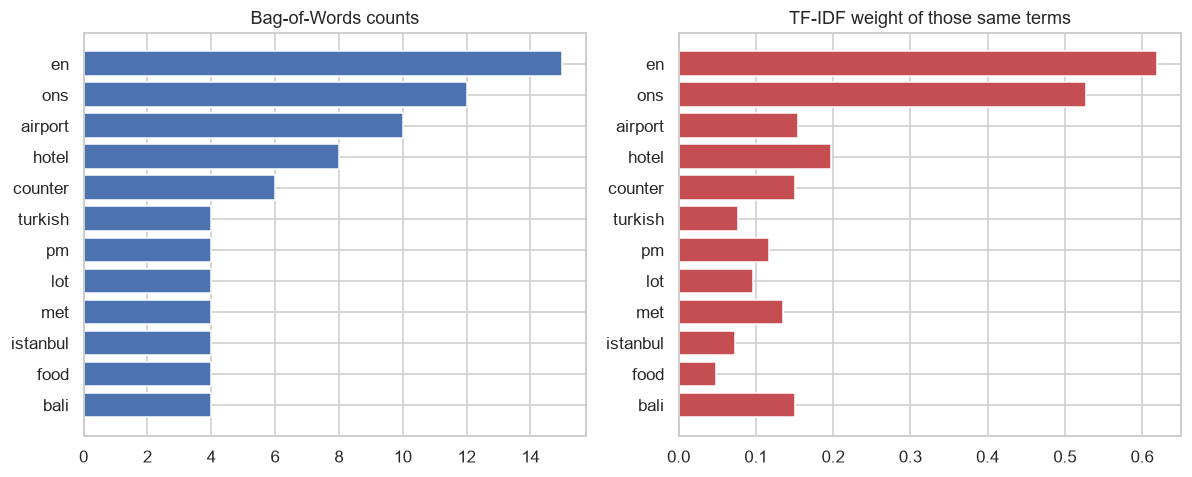

In [13]:
TOKEN = r"(?u)\b[a-zA-Z]{2,}\b"
vector_kwargs = dict(stop_words="english", token_pattern=TOKEN, min_df=5, max_df=0.85, max_features=3000)

bow = CountVectorizer(**vector_kwargs)
tfidf_vec = TfidfVectorizer(**vector_kwargs, norm="l2", smooth_idf=True)
X_bow = bow.fit_transform(df["review_clean"])
X_tfidf = tfidf_vec.fit_transform(df["review_clean"])
bow_terms = np.array(bow.get_feature_names_out())
tfidf_terms = np.array(tfidf_vec.get_feature_names_out())

print(f"BOW shape: {X_bow.shape}, stored entries: {X_bow.nnz:,}, sparsity: {1 - X_bow.nnz / np.prod(X_bow.shape):.2%}")
print(f"TF-IDF shape: {X_tfidf.shape}, stored entries: {X_tfidf.nnz:,}, sparsity: {1 - X_tfidf.nnz / np.prod(X_tfidf.shape):.2%}")
RESULTS["vocab_size"] = int(len(bow_terms))

bow_total = np.asarray(X_bow.sum(axis=0)).ravel()
top_bow = pd.DataFrame({"term": bow_terms, "count": bow_total}).sort_values("count", ascending=False).head(15)
print("Most frequent terms (Bag of Words, after stop-word removal):")
display(top_bow.reset_index(drop=True))

# One review: high raw counts versus TF-IDF weights, same vocabulary order.
shared = bow_terms.tolist() == tfidf_terms.tolist()
print("BOW and TF-IDF share the same term list:", shared)
doc_i = int(df["review_clean"].str.len().idxmax())
bow_row = np.asarray(X_bow[doc_i].todense()).ravel()
tfidf_row = np.asarray(X_tfidf[doc_i].todense()).ravel()
order = np.argsort(bow_row)[::-1][:12]
side = pd.DataFrame({
    "term": bow_terms[order],
    "count": bow_row[order].astype(int),
    "tfidf": tfidf_row[order],
})
print(f"Highest counts in review {doc_i} (airline={df.loc[doc_i, 'Airline']}, overall={df.loc[doc_i, 'Overall Rating']}):")
display(side.round(4))
print(df.loc[doc_i, "Reviews"][:500])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(side["term"][::-1], side["count"][::-1], color="#4C72B0")
axes[0].set_title("Bag-of-Words counts")
axes[1].barh(side["term"][::-1], side["tfidf"][::-1], color="#C44E52")
axes[1].set_title("TF-IDF weight of those same terms")
save_fig(fig, "18_bow_vs_tfidf.png")
top_bow.to_csv(OUT / "bow_top_terms.csv", index=False)

Cosine similarity for 12 reviews (6 low overall scores, then 6 high):


,Singapo:1,All:1,Japan:1,Air:1,Qatar:1,Cathay:2,Singapo:9,All:10,Japan:9,Air:9,Qatar:9,Cathay:9
Singapo:1,1.00,0.06,0.03,0.04,0.03,0.09,0.11,0.03,0.03,0.02,0.04,0.03
All:1,0.06,1.00,0.05,0.01,0.14,0.11,0.07,0.08,0.04,0.06,0.06,0.03
Japan:1,0.03,0.05,1.00,0.09,0.01,0.05,0.01,0.01,0.02,0.07,0.01,0.01
Air:1,0.04,0.01,0.09,1.00,0.00,0.02,0.02,0.00,0.02,0.11,0.02,0.03
Qatar:1,0.03,0.14,0.01,0.00,1.00,0.05,0.10,0.02,0.03,0.09,0.03,0.01
Cathay:2,0.09,0.11,0.05,0.02,0.05,1.00,0.04,0.00,0.03,0.02,0.01,0.05
Singapo:9,0.11,0.07,0.01,0.02,0.10,0.04,1.00,0.06,0.01,0.02,0.03,0.04
All:10,0.03,0.08,0.01,0.00,0.02,0.00,0.06,1.00,0.02,0.02,0.01,0.05
Japan:9,0.03,0.04,0.02,0.02,0.03,0.03,0.01,0.02,1.00,0.00,0.11,0.09
Air:9,0.02,0.06,0.07,0.11,0.09,0.02,0.02,0.02,0.00,1.00,0.02,0.03


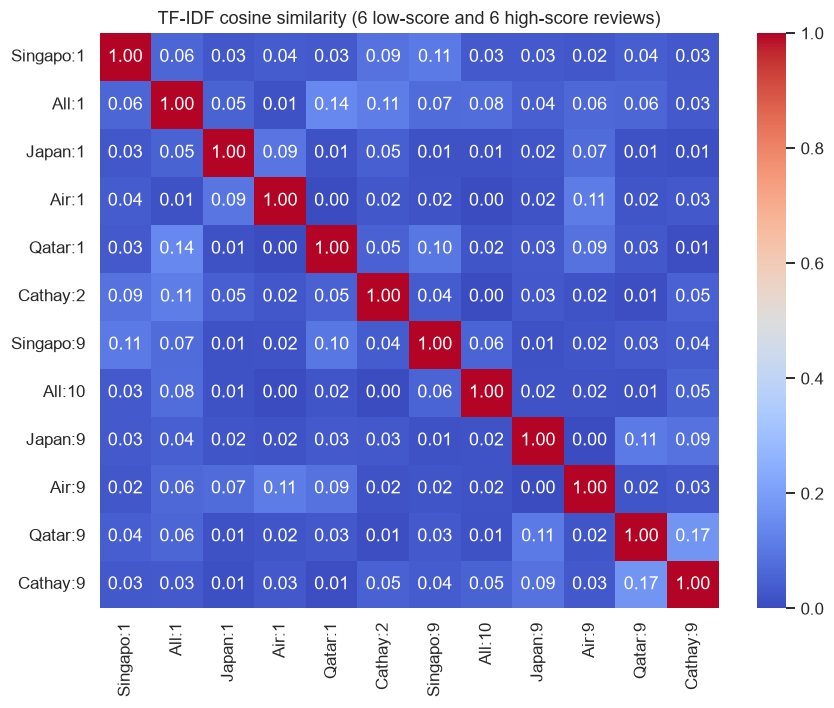

Cosine summary on a 300-review block (upper triangle, TF-IDF):
  all pairs: mean 0.046, median 0.039
  both recommended: 0.055
  both not recommended: 0.047
  one of each: 0.040
Query 6669: Air France | Economy Class | overall 1 | recommended no
Malé to Paris CDG. Air France has overbooked our flight of 18 passengers. I was trying to understand what I had to do to fly and they all refused to talk to me at first. We were a lot of people waiting to be checked in. In the end, when I started complaining, they all answered “I don’t care I don’t work for Air France” indeed they were representative hired by Air France but none of their staff were actually present. 
Mean cosine to 200 random reviews: 0.047


,neighbor,cosine,airline,overall,recommended,snippet
0,6166,0.345,Air France,1,no,I have flown with Air France regularly because...
1,6110,0.335,Air France,1,no,We booked our flight through air France from T...
2,6818,0.327,Air France,2,no,Los Angeles to Paris CDG in Business Class in ...


Query 96: Singapore Airlines | First Class | overall 10 | recommended yes
Suites on the A380 are in terms of comfort and layout 100% better than on the SQ 777 although the high standard of service remains the same for both aircraft. Lovely welcome from the staff and the cabin crew are exceptionally well presented in grooming and demeanour.  I also am appreciative that I was addressed by my title and surname as I am of that older generation that appreciates such niceties. The suite very com
Mean cosine to 200 random reviews: 0.036


,neighbor,cosine,airline,overall,recommended,snippet
0,1036,0.239,Qatar Airways,10,yes,It was an absolutely lovely experience and the...
1,64,0.232,Singapore Airlines,10,yes,I have just flown SQ256 from Brisbane to Singa...
2,193,0.231,Singapore Airlines,9,yes,"Nice flights, first leg got Premium Economy se..."


In [14]:
def diverse_positions(frame, n, seed):
    picked = []
    for _, g in frame.groupby("Airline"):
        picked.append(int(g.sample(1, random_state=seed).index[0]))
    pool = frame.loc[picked]
    if len(pool) <= n:
        return pool.index.to_numpy()
    return pool.sample(n, random_state=seed).index.to_numpy()


low_pos = diverse_positions(df[df["Overall Rating"] <= 2], 6, RANDOM_STATE)
high_pos = diverse_positions(df[df["Overall Rating"] >= 9], 6, RANDOM_STATE)
heat_pos = np.concatenate([low_pos, high_pos])
S = cosine_similarity(X_tfidf[heat_pos])
heat_labels = [
    f"{df.loc[i, 'Airline'].split()[0][:7]}:{int(df.loc[i, 'Overall Rating'])}"
    for i in heat_pos
]
heat_df = pd.DataFrame(S, index=heat_labels, columns=heat_labels)
print("Cosine similarity for 12 reviews (6 low overall scores, then 6 high):")
display(heat_df.round(2))
heat_df.round(4).to_csv(OUT / "cosine_heatmap_12.csv")

fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(heat_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1, ax=ax)
ax.set_title("TF-IDF cosine similarity (6 low-score and 6 high-score reviews)")
save_fig(fig, "19_cosine_heatmap.png")

block_pos = df.sample(300, random_state=RANDOM_STATE).index.to_numpy()
S_block = cosine_similarity(X_tfidf[block_pos])
iu = np.triu_indices(len(block_pos), k=1)
pair_cos = S_block[iu]
rec_flag = df.loc[block_pos, "Recommended"].str.lower().eq("yes").to_numpy()
both_yes = rec_flag[:, None] & rec_flag[None, :]
both_no = (~rec_flag)[:, None] & (~rec_flag)[None, :]
mixed = rec_flag[:, None] ^ rec_flag[None, :]
print("Cosine summary on a 300-review block (upper triangle, TF-IDF):")
print(f"  all pairs: mean {pair_cos.mean():.3f}, median {np.median(pair_cos):.3f}")
print(f"  both recommended: {S_block[iu][both_yes[iu]].mean():.3f}")
print(f"  both not recommended: {S_block[iu][both_no[iu]].mean():.3f}")
print(f"  one of each: {S_block[iu][mixed[iu]].mean():.3f}")
RESULTS["cosine_all_mean"] = float(pair_cos.mean())
RESULTS["cosine_both_yes"] = float(S_block[iu][both_yes[iu]].mean())
RESULTS["cosine_both_no"] = float(S_block[iu][both_no[iu]].mean())
RESULTS["cosine_mixed"] = float(S_block[iu][mixed[iu]].mean())


def show_neighbors(query_pos, n_neighbors=3):
    sims = cosine_similarity(X_tfidf[query_pos], X_tfidf).ravel()
    sims[query_pos] = -1
    order = np.argsort(sims)[::-1][:n_neighbors]
    rng = np.random.default_rng(RANDOM_STATE)
    candidates = np.delete(np.arange(len(df)), query_pos)
    baseline_idx = rng.choice(candidates, size=200, replace=False)
    baseline = float(cosine_similarity(X_tfidf[query_pos], X_tfidf[baseline_idx]).mean())
    q = df.loc[query_pos]
    print("=" * 80)
    print(
        f"Query {query_pos}: {q['Airline']} | {q['Class']} | overall {q['Overall Rating']} | "
        f"recommended {q['Recommended']}"
    )
    print(q["Reviews"][:420].replace("\n", " "))
    print(f"Mean cosine to 200 random reviews: {baseline:.3f}")
    rows = []
    for j in order:
        other = df.loc[int(j)]
        rows.append({
            "neighbor": int(j),
            "cosine": sims[j],
            "airline": other["Airline"],
            "overall": int(other["Overall Rating"]),
            "recommended": other["Recommended"],
            "snippet": other["Reviews"][:180].replace("\n", " "),
        })
    display(pd.DataFrame(rows).round(3))


low_query = int(df[df["Overall Rating"] == 1].sample(1, random_state=RANDOM_STATE).index[0])
high_query = int(df[df["Overall Rating"] == 10].sample(1, random_state=RANDOM_STATE).index[0])
show_neighbors(low_query)
show_neighbors(high_query)

Terms with the largest gap in mean TF-IDF:


,term,yes_minus_no,side
2722,told,-0.0217,higher when not recommended
659,customer,-0.0206,higher when not recommended
2702,ticket,-0.0190,higher when not recommended
2787,turkish,-0.0166,higher when not recommended
1269,hours,-0.0164,higher when not recommended
2301,said,-0.0155,higher when not recommended
2977,worst,-0.0151,higher when not recommended
1575,luggage,-0.0142,higher when not recommended
175,asked,-0.0133,higher when not recommended
1380,istanbul,-0.0132,higher when not recommended


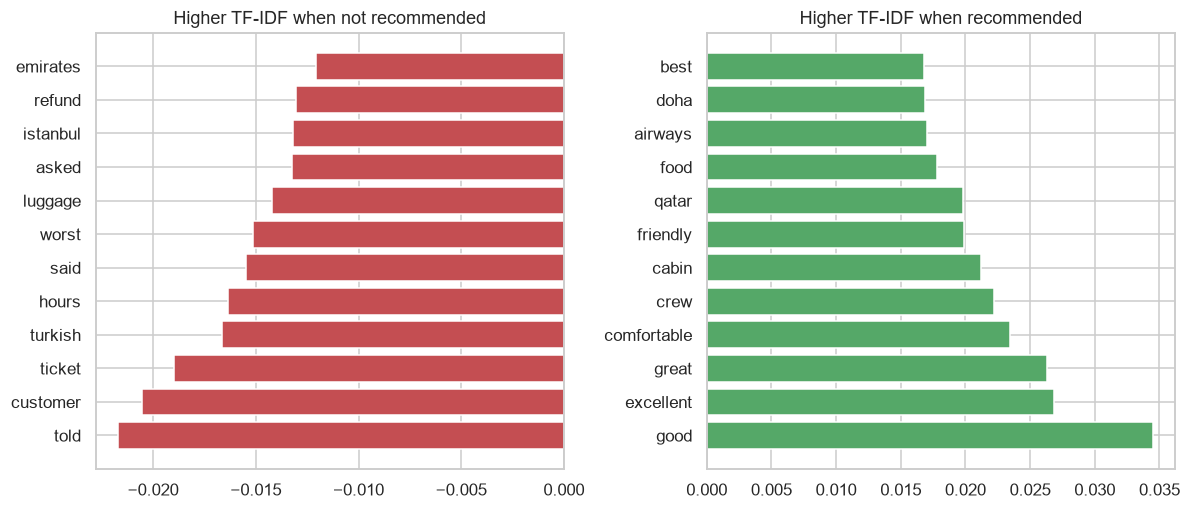

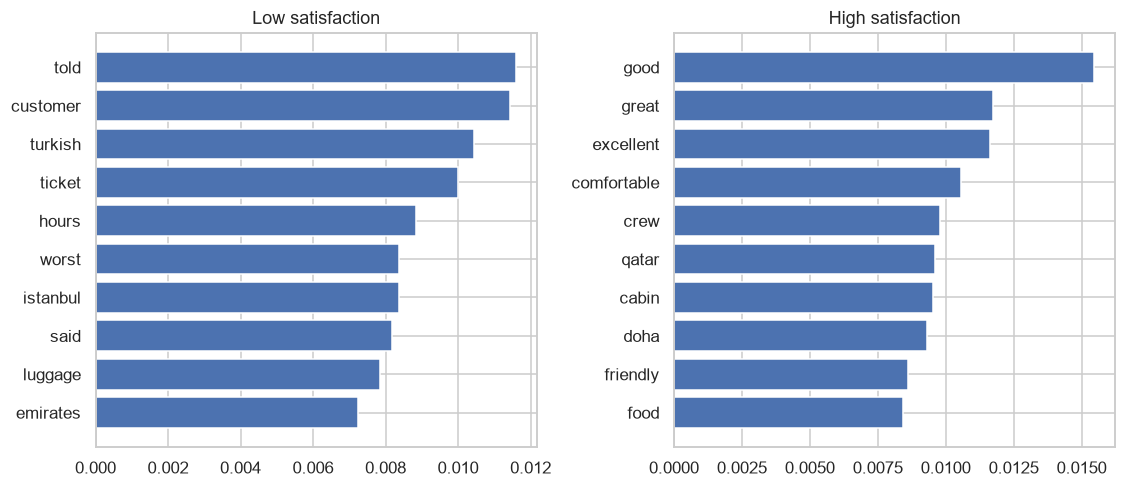

In [15]:
yes_mask = df["Recommended"].str.lower().eq("yes").to_numpy()
mean_yes = np.asarray(X_tfidf[yes_mask].mean(axis=0)).ravel()
mean_no = np.asarray(X_tfidf[~yes_mask].mean(axis=0)).ravel()
diff = mean_yes - mean_no
term_diff = pd.DataFrame({"term": tfidf_terms, "yes_minus_no": diff})
top_pos = term_diff.nlargest(12, "yes_minus_no")
top_neg = term_diff.nsmallest(12, "yes_minus_no").sort_values("yes_minus_no")
term_table = pd.concat([
    top_neg.assign(side="higher when not recommended"),
    top_pos.assign(side="higher when recommended"),
])
term_table.to_csv(OUT / "tfidf_by_recommendation.csv", index=False)
print("Terms with the largest gap in mean TF-IDF:")
display(term_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].barh(top_neg["term"], top_neg["yes_minus_no"], color="#C44E52")
axes[0].set_title("Higher TF-IDF when not recommended")
axes[1].barh(top_pos["term"], top_pos["yes_minus_no"], color="#55A868")
axes[1].set_title("Higher TF-IDF when recommended")
save_fig(fig, "20_terms_by_recommendation.png")

global_mean = np.asarray(X_tfidf.mean(axis=0)).ravel()
cluster_term_rows = []
fig, axes = plt.subplots(1, df["kmeans"].nunique(), figsize=(5.2 * df["kmeans"].nunique(), 4.6), squeeze=False)
for ax, (lab, g) in zip(axes[0], df.groupby("kmeans")):
    local = np.asarray(X_tfidf[g.index].mean(axis=0)).ravel()
    distinct = local - global_mean
    top_idx = np.argsort(distinct)[-10:]
    ax.barh(tfidf_terms[top_idx], distinct[top_idx], color="#4C72B0")
    ax.set_title(k_names[lab])
    for term, score in zip(tfidf_terms[top_idx], distinct[top_idx]):
        cluster_term_rows.append({"cluster": k_names[lab], "term": term, "distinctiveness": score})
save_fig(fig, "21_terms_by_cluster.png")
pd.DataFrame(cluster_term_rows).to_csv(OUT / "tfidf_by_kmeans_cluster.csv", index=False)

## 11. Results to carry into the report

The block below reprints the numbers this run produced: cleaning counts, the selected parameters, the silhouette scores, and the cosine summary. Figures are in `figures/` and tables are in `outputs/`.

In [16]:
summary_lines = [
    f"Clean reviews used: {RESULTS['n_clean']} (started from {len(raw)}).",
    f"Verified flags corrected: {RESULTS['n_verified_fixed']}. Duplicate reviews removed: {RESULTS['n_duplicate_reviews']}.",
    f"Inflight Entertainment zeros imputed with median {RESULTS['ife_median_imputed']:.0f}: {RESULTS['n_ife_zero']}.",
    f"IQR flags on rating columns: {RESULTS['rating_iqr_flags']}.",
    f"Share of overall ratings in {{1, 2, 9, 10}}: {RESULTS['extreme_overall_share']:.1%}.",
    f"Correlation of Value For Money and Overall Rating: {RESULTS['corr_value_overall']:.3f}.",
    f"Two-component PCA of the ratings explains {RESULTS['pc_variance_2d']:.1%} of variance.",
    f"Mixed-feature PCA kept {RESULTS['mixed_pca_components']} components ({RESULTS['mixed_pca_variance']:.1%} variance).",
    f"K-Means: K={RESULTS['kmeans_k']}, silhouette={RESULTS['kmeans_silhouette']:.4f}, inertia={RESULTS['kmeans_inertia']:.1f}.",
    f"Hierarchical: {RESULTS['hier_method']} linkage, K={RESULTS['hier_k']}, silhouette={RESULTS['hier_silhouette']:.4f}.",
    "Cophenetic correlations: " + ", ".join(f"{k}={v:.3f}" for k, v in RESULTS["cophenetic"].items()) + ".",
    f"DBSCAN: eps={RESULTS['dbscan_eps']:.3f}, min_samples={RESULTS['dbscan_min_samples']}, "
    f"clusters={RESULTS['dbscan_clusters']}, noise={RESULTS['dbscan_noise']:.1%}, "
    f"silhouette={RESULTS['dbscan_silhouette']:.4f}.",
    f"TF-IDF vocabulary size: {RESULTS['vocab_size']}.",
    f"Toy cosine doc1-doc2={RESULTS['toy_cos_12']:.3f}, doc1-doc3={RESULTS['toy_cos_13']:.3f}.",
    f"Mean cosine in a 300-review block: all={RESULTS['cosine_all_mean']:.3f}, "
    f"both recommended={RESULTS['cosine_both_yes']:.3f}, "
    f"both not recommended={RESULTS['cosine_both_no']:.3f}, "
    f"mixed={RESULTS['cosine_mixed']:.3f}.",
]
print("\n".join(summary_lines))
(OUT / "key_results.txt").write_text("\n".join(summary_lines), encoding="utf-8")
print("\nK-Means profile:")
display(k_profile.round(3))
print("Feature-set comparison:")
display(feat_table.round(4))

Clean reviews used: 8098 (started from 8100).
Verified flags corrected: 3. Duplicate reviews removed: 2.
Inflight Entertainment zeros imputed with median 4: 1.
IQR flags on rating columns: 0.
Share of overall ratings in {1, 2, 9, 10}: 63.8%.
Correlation of Value For Money and Overall Rating: 0.883.
Two-component PCA of the ratings explains 55.3% of variance.
Mixed-feature PCA kept 13 components (91.5% variance).
K-Means: K=2, silhouette=0.2708, inertia=34573.6.
Hierarchical: average linkage, K=2, silhouette=0.2471.
Cophenetic correlations: ward=0.551, complete=0.550, average=0.618.
DBSCAN: eps=0.877, min_samples=12, clusters=5, noise=8.8%, silhouette=-0.0819.
TF-IDF vocabulary size: 3000.
Toy cosine doc1-doc2=0.372, doc1-doc3=0.794.
Mean cosine in a 300-review block: all=0.046, both recommended=0.055, both not recommended=0.047, mixed=0.040.

K-Means profile:


,cluster,n,pct,recommend_rate,top_class,top_airline,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,name
0,0,3670,45.32,0.064,Economy Class,Turkish Airlines,3.032,3.121,3.071,3.407,1.638,2.205,Low satisfaction
1,1,4428,54.68,0.915,Economy Class,Qatar Airways,3.732,3.942,3.644,3.828,4.400,8.473,High satisfaction


Feature-set comparison:


,feature_space,best_k,silhouette
0,6 ratings (main),2,0.2708
1,"5 ratings, no overall",2,0.2244
2,4 service scores only,8,0.2610
3,Mixed features + PCA 90%,2,0.2085


## 12. How to use this in the technical report

Write the PDF in your own words. The notebook already contains the calculations and figures.

| Report section | Where the evidence is |
| --- | --- |
| Data cleaning | Section 4, `outputs/iqr_screen.csv`, figure 04 |
| Why standardisation, binning, one-hot, PCA | Section 5, scaler table, loadings, figures 05–06 |
| K-Means mechanics, elbow, silhouette, centres | Section 6, figures 07–10 |
| Linkage methods and the dendrogram | Section 7, figures 11–12 |
| DBSCAN eps, min_samples, noise | Section 8, figures 13–14 |
| Why one model fits this geometry better | Sections 9 and 11, `outputs/model_comparison.csv`, figure 15 |
| How the feature set changes the score | `outputs/feature_set_comparison.csv`, figure 16 |
| BOW, TF-IDF, cosine, with a numeric example | Section 10, figures 18–21 |
| Domain reading and limits | Cluster profiles, recommendation rates, term charts |

Points the profiles are meant to support, once you check them against the printed tables:

- Overall scores are polarised, and value-for-money moves with the overall score, so a two-group partition is a low-satisfaction group and a high-satisfaction group.
- K-Means and Ward linkage both cut that pattern into compact groups. DBSCAN only finds a group when a density gap exists. If its silhouette is lower or its noise share is high, the ratings behave like a filled cloud with two poles, not like well-separated blobs.
- TF-IDF down-weights words that sit in almost every review. Cosine neighbours should share a complaint or a compliment, and the mean TF-IDF gaps name the words that mark recommended versus not recommended reviews.

Limits to state honestly: silhouette on this survey is modest because many reviews sit between the two poles; there is no ground-truth segment label; `Route` was left out because of cardinality; English stop-words remove some function words and also some useful ones; the 12-review heatmap is an illustration, while the 300-review means are the summary; the CNN bonus is a separate image problem.

Kaggle link for the cover of the report: https://www.kaggle.com/datasets/elijahconnectng/airlines-review-dataset